### Desafio 4 - Predicción de renuncia de clientes

- Nombre: Jose Ignacio Kuoman Jimenez
- Generacion: G83

#### Descripción

Contamos con una base de datos de una compañía de telecomunicaciones, con la que la 
misma podrá tomar acciones dirigidas en la retención de clientes propensos a la fuga.

La base de datos cuenta con 12 atributos regresores más la etiqueta de clase que son:
o
- Call Failures: Número de fallos de llamadas
- Complaints: Quejas (1) o ninguna queja (0)
- Subscription Length: Meses totales de suscripción
- Charge Amount: Importe del cargo, atributo ordinal (0: importe más bajo, 9: importe más 
alt)
- Seconds of Use: Segundos totales de llamadas.
- Frequency of use: Número total de llamadas
- Frequency of SMS: Número total de mensajes de texto
- Distinct Called Numbers: Número total de llamadas distintas
- Age Group: Grupo de edad, atributo ordinal (1: menor edad, 5: mayor edad)
- Tariff Plan: Plan de tarifa, binario (1: pago por uso, 2: contractual)
- Status: Estado, binario (1: activo, 2: inactivo)
- Churn: Renuncia, binario (1: cancelación, 0: no cancelación) - Etiqueta de clase
- Customer Value: El valor calculado del clienteon:

A partir de estos datos se te solicita lo siguiente:

#### Pregunta 1

**1**. Importa las librerías necesarias para aplicar preprocesamiento de datos, visualización y creación de un modelo de red neuronal feedforward con Keras y Tensorflow. Importa la base de datos Customer Churn.csv y realiza el preprocesamiento de los datos

Importamos las librerías que nos solicitan y otras librerias adicionales para desarrollar el desafío

In [18]:
# Para el preprocesamiento de los datos y visualización de los datos
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [20]:
# Para realizar la estandarización de las variables regresoras
from sklearn.preprocessing import StandardScaler

In [22]:
# Para balancear las clases
from imblearn.over_sampling import SMOTE

In [24]:
# para la division del conjunto de datos de entrenamiento y de test
from sklearn.model_selection import train_test_split

In [26]:
# para instanciar el modelo Random Forest Classifier
from sklearn.ensemble import RandomForestClassifier

# para calcular las metricas del modelo
from sklearn.metrics import f1_score, classification_report

In [28]:
# Importación de librerias para el desarrollo de red neuronal artificial

import tensorflow as tf
from keras.models import Sequential
from keras.layers import Dense
from keras.optimizers import SGD
import keras

Importamos la base de datos Customer Churn.csv

In [30]:
# Importamos la base de datos
df = pd.read_csv('Customer Churn.csv')

In [32]:
df.head()

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0
3,10,0,38,0,4198,66,1,35,1,1,1,15,240.020,0
4,3,0,38,0,2393,58,2,33,1,1,1,15,145.805,0


##### Realizamos el preprocesamiento de los datos

In [34]:
df.shape

(3150, 14)

Tenemos 3150 columnas y 14 columnas ( 14 características)

In [36]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3150 entries, 0 to 3149
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Call  Failure            3150 non-null   int64  
 1   Complains                3150 non-null   int64  
 2   Subscription  Length     3150 non-null   int64  
 3   Charge  Amount           3150 non-null   int64  
 4   Seconds of Use           3150 non-null   int64  
 5   Frequency of use         3150 non-null   int64  
 6   Frequency of SMS         3150 non-null   int64  
 7   Distinct Called Numbers  3150 non-null   int64  
 8   Age Group                3150 non-null   int64  
 9   Tariff Plan              3150 non-null   int64  
 10  Status                   3150 non-null   int64  
 11  Age                      3150 non-null   int64  
 12  Customer Value           3150 non-null   float64
 13  Churn                    3150 non-null   int64  
dtypes: float64(1), int64(13)

##### Ver si hay valores nulos en los datos

In [38]:
df.isna().sum()

Call  Failure              0
Complains                  0
Subscription  Length       0
Charge  Amount             0
Seconds of Use             0
Frequency of use           0
Frequency of SMS           0
Distinct Called Numbers    0
Age Group                  0
Tariff Plan                0
Status                     0
Age                        0
Customer Value             0
Churn                      0
dtype: int64

##### Revisamos la distribución de los datos de las variables

In [40]:
df.describe()

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
count,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000
mean,7.627937,0.076508,32.541905,0.942857,4472.459683,69.460635,73.174921,23.509841,2.826032,1.077778,1.248254,30.998413,470.972916,0.157143
std,7.263886,0.265851,8.573482,1.521072,4197.908687,57.413308,112.237560,17.217337,0.892555,0.267864,0.432069,8.831095,517.015433,0.363993
min,0.000000,0.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,15.000000,0.000000,0.000000
25%,1.000000,0.000000,30.000000,0.000000,1391.250000,27.000000,6.000000,10.000000,2.000000,1.000000,1.000000,25.000000,113.801250,0.000000
50%,6.000000,0.000000,35.000000,0.000000,2990.000000,54.000000,21.000000,21.000000,3.000000,1.000000,1.000000,30.000000,228.480000,0.000000
75%,12.000000,0.000000,38.000000,1.000000,6478.250000,95.000000,87.000000,34.000000,3.000000,1.000000,1.000000,30.000000,788.388750,0.000000
max,36.000000,1.000000,47.000000,10.000000,17090.000000,255.000000,522.000000,97.000000,5.000000,2.000000,2.000000,55.000000,2165.280000,1.000000


##### Generamos una función para representar gráficamente la distribución de los datos de las variables categoricas y continuas

In [42]:
def representacion_de_las_variables(df):
    plt.figure(figsize = (15, 11))

    for idx, col in enumerate(df.columns):
        
        # La numeracion de los subplot comienza 1, por lo que se usa idx+1.
        # idx+1 ademas te va indicar en que columna estas
        plt.subplot(4, 4, idx+1)
        plt.title(col)
        plt.xlabel('')

        if len(df[col].unique()) > 11:
            sns.histplot(x=col, kde = True, data=df)

        else:
            sns.countplot(y=df[col], hue=df[col], palette='viridis', dodge=False)

        plt.tight_layout()

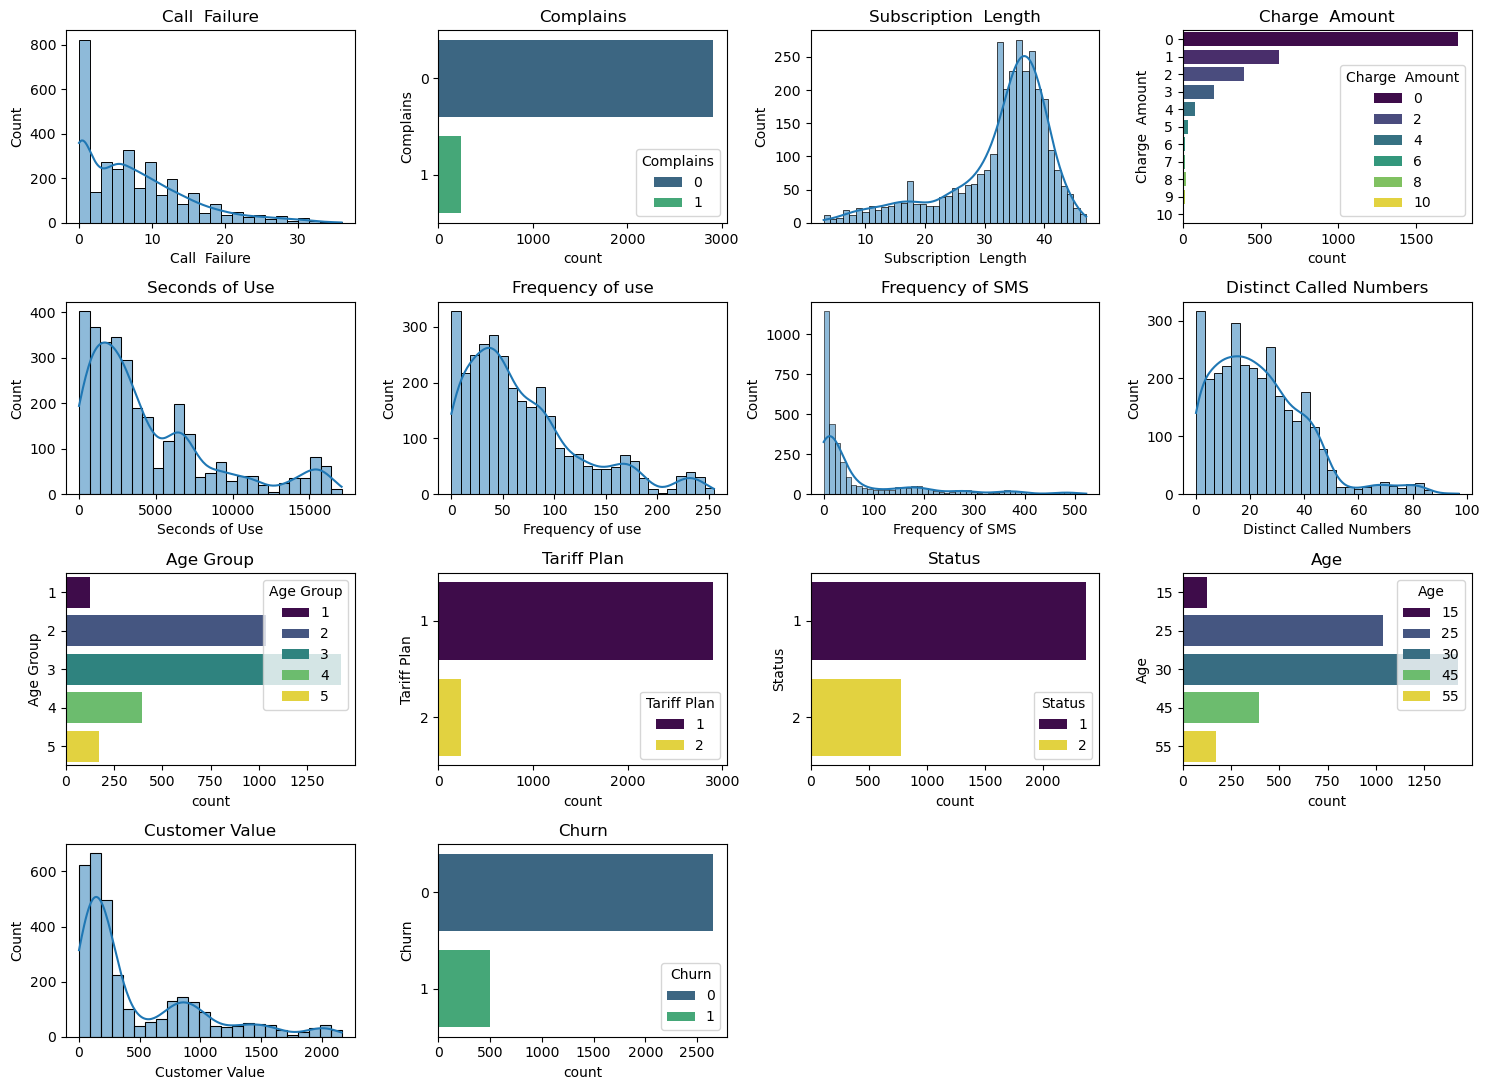

In [44]:
representacion_de_las_variables(df)

##### Creamos una función que me brinde una lista de las variables categoricas y una lista de las variables continuas del conjunto de datos que vamos a analizar

In [46]:
def listado_de_variables(df):
    list_var_cont = []
    list_var_cate = []

    for idx, col in enumerate(df.columns):
    
        if len(df[col].unique()) > 11:
            list_var_cont.append(col)
        else:
            list_var_cate.append(col)

    return list_var_cate, list_var_cont

Pasamos a ver con mayor detalle algunas variables categoricas

In [48]:
df['Charge  Amount'].value_counts().sort_index()

Charge  Amount
0     1768
1      617
2      395
3      199
4       76
5       30
6       11
7       14
8       19
9       14
10       7
Name: count, dtype: int64

Existe una categoría con el importe más cargo, que vendría a ser el número 10 y no 9 como señalaba el problema.

In [51]:
df['Age Group'].value_counts().sort_index()

Age Group
1     123
2    1037
3    1425
4     395
5     170
Name: count, dtype: int64

In [53]:
df['Age'].value_counts().sort_index()

Age
15     123
25    1037
30    1425
45     395
55     170
Name: count, dtype: int64

In [55]:
df.columns

Index(['Call  Failure', 'Complains', 'Subscription  Length', 'Charge  Amount',
       'Seconds of Use', 'Frequency of use', 'Frequency of SMS',
       'Distinct Called Numbers', 'Age Group', 'Tariff Plan', 'Status', 'Age',
       'Customer Value', 'Churn'],
      dtype='object')

In [57]:
list_var_cate, list_var_cont = listado_de_variables(df)

##### Listado de variables categoricas

In [59]:
list_var_cate

['Complains',
 'Charge  Amount',
 'Age Group',
 'Tariff Plan',
 'Status',
 'Age',
 'Churn']

Vemos que hay 7 variables categoricas:
- Complains
- Charge  Amount
- Age Group
- Tariff Plan
- Status
- Age
- Churn

##### Listado de variables continuas

In [61]:
list_var_cont

['Call  Failure',
 'Subscription  Length',
 'Seconds of Use',
 'Frequency of use',
 'Frequency of SMS',
 'Distinct Called Numbers',
 'Customer Value']

Vemos que hay 7 variables continuas:

- Call  Failure
- Subscription  Length
- Seconds of Use
- Frequency of use
- Frequency of SMS
- Distinct Called Numbers
- Customer Value

Dentro del preprocesamiento de los datos, pasamos a ver los outliers del conjunto de datos.

#### Procedemos a ver ahora los outliers del conjunto de datos

Usamos una función para graficar los outliers de las variables continuas

In [130]:
# Funcion para revisar los outliers

def plot_boxplot_with_outliers(data, column_name, outlier_color = 'red', factor = 1.5):
    # Calcular los estadísticos clave
    Q1 = data[column_name].quantile(0.25)
    Q3 = data[column_name].quantile(0.75)
    IQR = Q3 - Q1

    # Calcular los límites para los valores atípicos
    lower_bound = Q1 - factor * IQR
    upper_bound = Q3 + factor * IQR
    
    # Crear un gráfico de diagrama de caja (boxplot)
    plt.figure(figsize=(8,10))
    sns.boxplot(y=data[column_name], showfliers=False)

    # plt.title(f'Diagrama de Caja de {column_name}')
    plt.ylabel(column_name)
    plt.xlabel(i)
    
    # Resaltar los valores atípicos en un color diferente
    outliers = data[(data[column_name] < lower_bound) | (data[column_name] > upper_bound)]
    plt.scatter(y=outliers[column_name], x=[0]*len(outliers), color=outlier_color, label='Outliers')

    # Anotar los valores de límites y cuartiles en el gráfico
    plt.text(0.35, Q1-0.55, f'Q1: {Q1:.2f}', fontsize=10)
    plt.text(0.35, Q3+0.3, f'Q3: {Q3:.2f}', fontsize=10)
    plt.text(0.205, lower_bound, f'Límite Inferior: {lower_bound:.2f}',fontsize=10)
    plt.text(0.205, upper_bound, f'Límite Superior: {upper_bound:.2f}',fontsize=10)
    plt.legend()
    plt.show()
    
    return outliers

#### Revisamos los outliers de las variables continuas

Recordar que habíamos determinado previamente cuales eran las variables continuas, siendo estas 7:

- Call  Failure
- Subscription  Length
- Seconds of Use
- Frequency of use
- Frequency of SMS
- Distinct Called Numbers
- Customer Value

In [131]:
df_var_cont = df[list_var_cont]
df_var_cont

,Call Failure,Subscription Length,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Customer Value
0,8,38,4370,71,5,17,197.640
1,0,39,318,5,7,4,46.035
2,10,37,2453,60,359,24,1536.520
3,10,38,4198,66,1,35,240.020
4,3,38,2393,58,2,33,145.805
...,...,...,...,...,...,...,...
3145,21,19,6697,147,92,44,721.980
3146,17,17,9237,177,80,42,261.210
3147,13,18,3157,51,38,21,280.320
3148,7,11,4695,46,222,12,1077.640


##### Graficamos los outliers en las variables continuas

<Figure size 200x100 with 0 Axes>

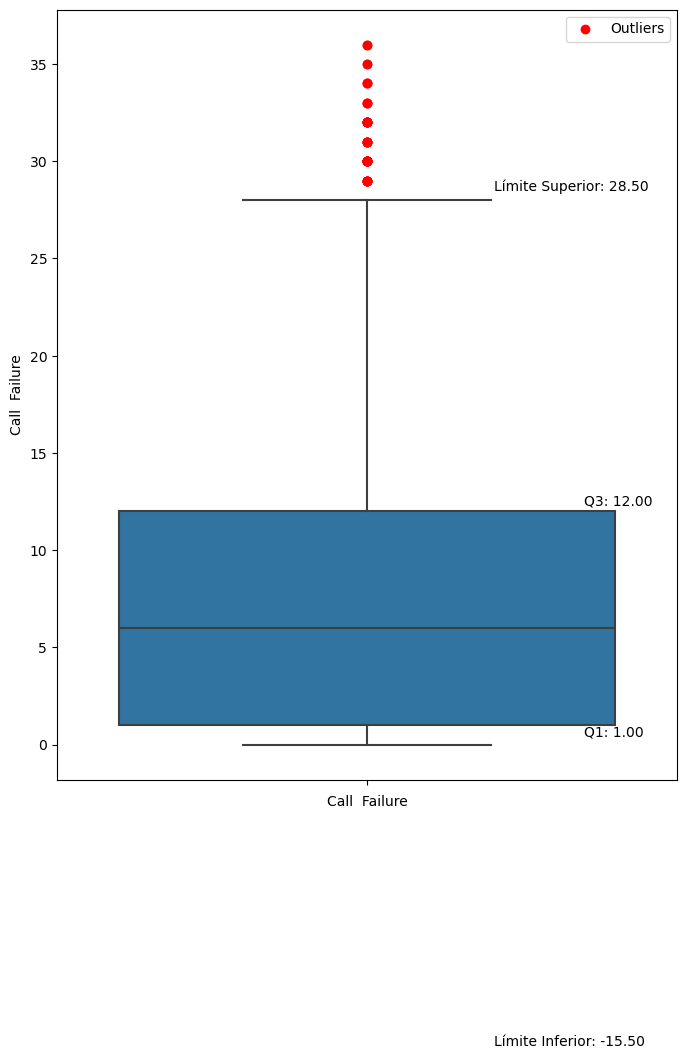

<Figure size 200x100 with 0 Axes>

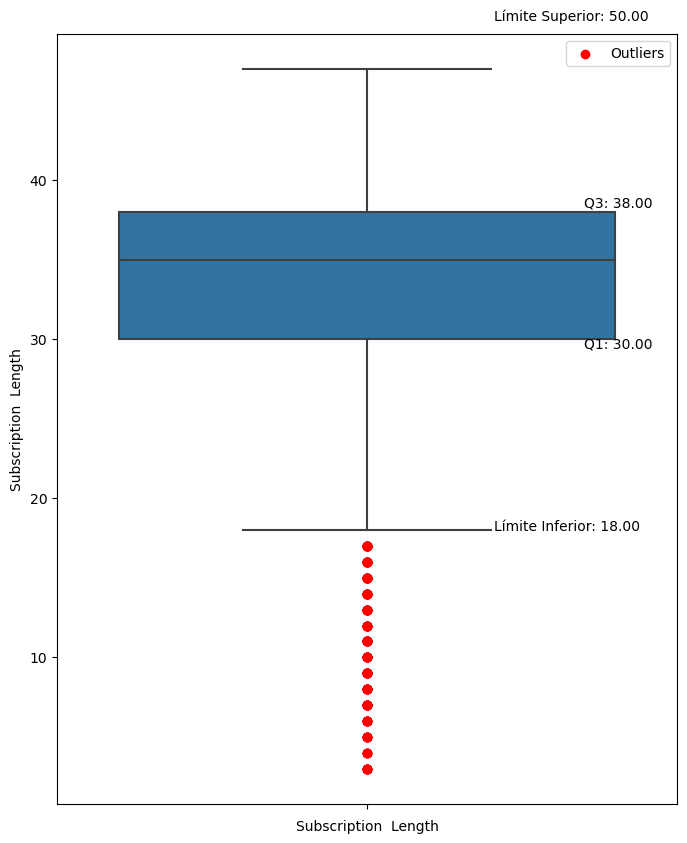

<Figure size 200x100 with 0 Axes>

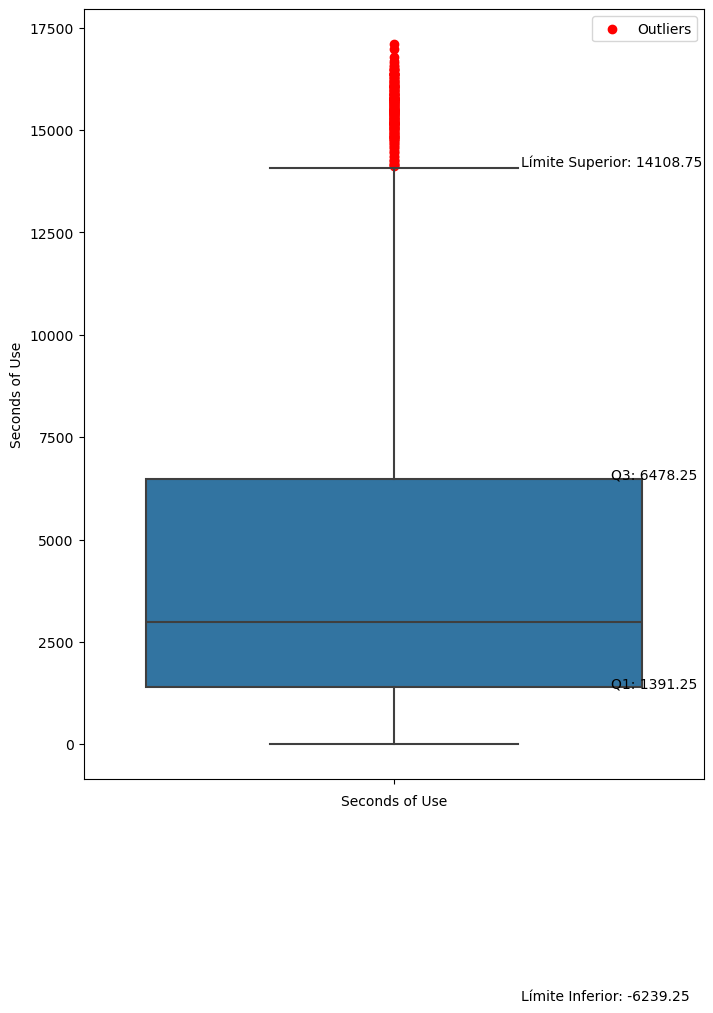

<Figure size 200x100 with 0 Axes>

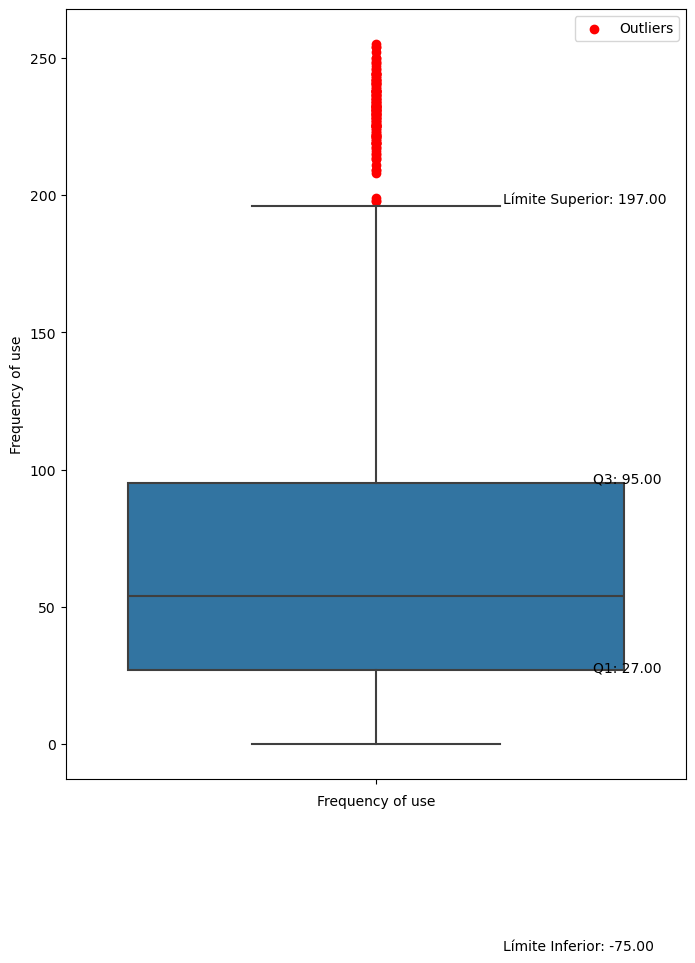

<Figure size 200x100 with 0 Axes>

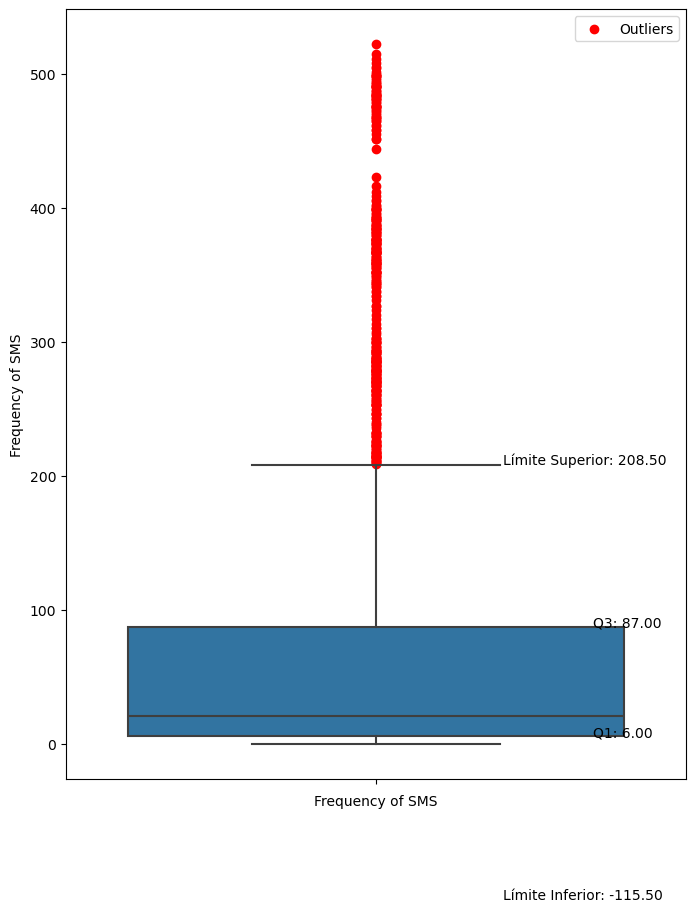

<Figure size 200x100 with 0 Axes>

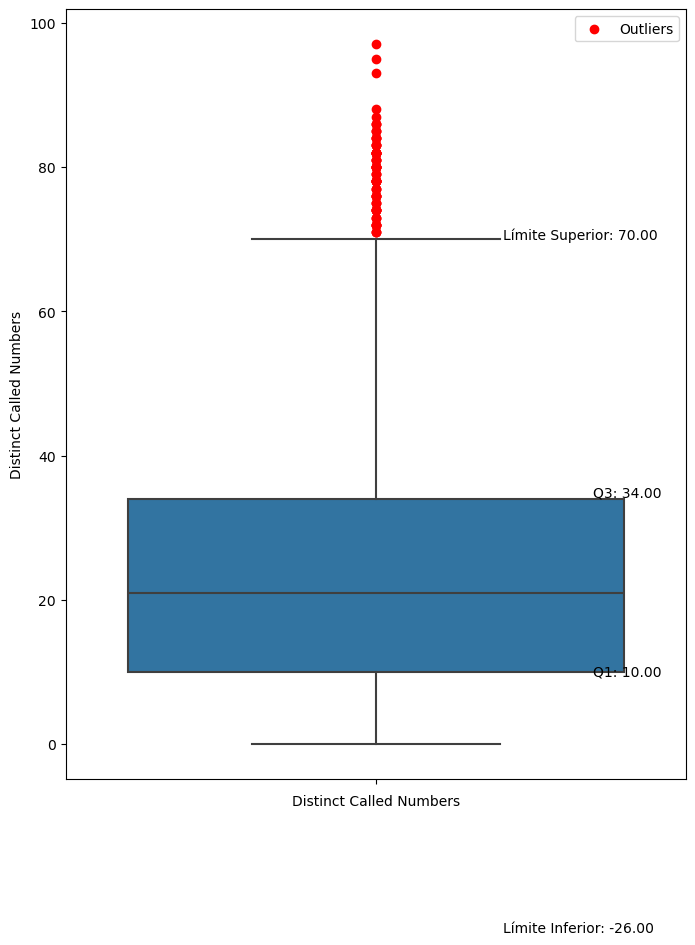

<Figure size 200x100 with 0 Axes>

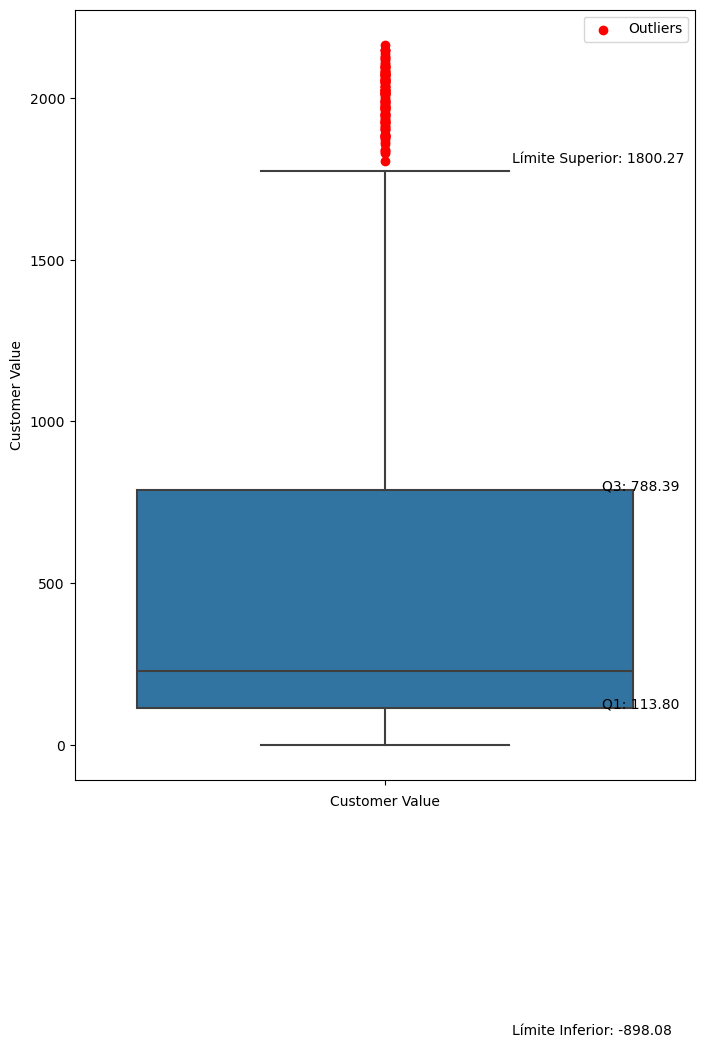

In [132]:
for i in df_var_cont.columns:
    plt.figure(figsize=(2, 1))
    plot_boxplot_with_outliers(data = df, column_name = i, outlier_color = 'red', factor = 1.5)

Podemos ver que en todas las variables continuas se tienen outliers, teniendo algunas variables mucho más outliers que otras. Por lo cual, procedemos a determinar la cantidad y la proporción de outliers en las variables continuas.

##### Determinamos la cantidad y la proporcion de outliers en las variables continuas

In [133]:
Q1 = df[list_var_cont].quantile(0.25)
Q3 = df[list_var_cont].quantile(0.75)
IQR = Q3 - Q1
# Recuento de outliers como recuento
((df[list_var_cont] < (Q1 - 1.5 * IQR)) | (df[list_var_cont] > (Q3 + 1.5 * IQR))).sum()

Call  Failure               47
Subscription  Length       282
Seconds of Use             200
Frequency of use           129
Frequency of SMS           368
Distinct Called Numbers     77
Customer Value             116
dtype: int64

In [134]:
# Recuento de outliers como %
((df[list_var_cont] < (Q1 - 1.5 * IQR)) | (df[list_var_cont] > (Q3 + 1.5 * IQR))).mean()

Call  Failure              0.014921
Subscription  Length       0.089524
Seconds of Use             0.063492
Frequency of use           0.040952
Frequency of SMS           0.116825
Distinct Called Numbers    0.024444
Customer Value             0.036825
dtype: float64

1. Podemos ver que la mayoría de variables tiene un poco más del 3% de sus datos con outliers.
2. Podemos ver que las variables con mayor % de outliers son las siguientes:
- Subscription  Length
- Seconds of Use
- Frequency of SMS

#### Pregunta 2

**2**. Analiza la distribución de “Subscription Length” para cada clase (Churn), describiendo si hay alguna incidencia de esta variable en la renuncia o no. Realiza una estandarización de las variables regresoras

##### A recordar:
- **Subscription Length**: Meses totales de suscripción
- **Churn**: Renuncia, binario (1: Cancelación, 0: No Cancelación) - Etiqueta de clase

##### Analizamos la distribución de la variable “Subscription Length” para cada clase de la variable "Churn"

<Axes: xlabel='Churn', ylabel='Subscription  Length'>

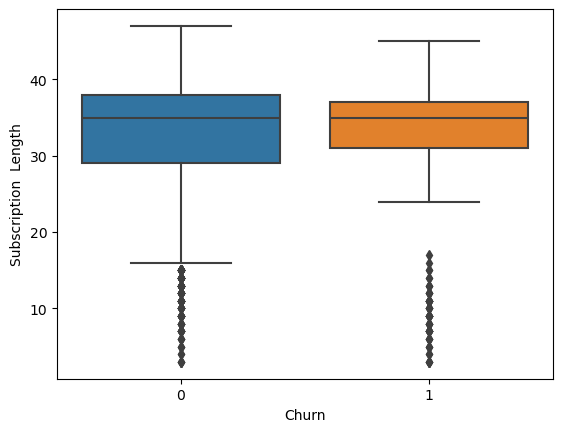

In [135]:
sns.boxplot(data = df, x = 'Churn', y = 'Subscription  Length')

Habíamos visto recientemente que una de las variables con mayor cantidad de outliers era Subscription  Length con casi un 9% del total de sus datos con valores outliers.

##### Realizamos un Histograma

Se realizará un histograma para entender mejor la distribución de los datos de “Subscription Length” para cada clase de "Churn".

C:\Users\josek\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


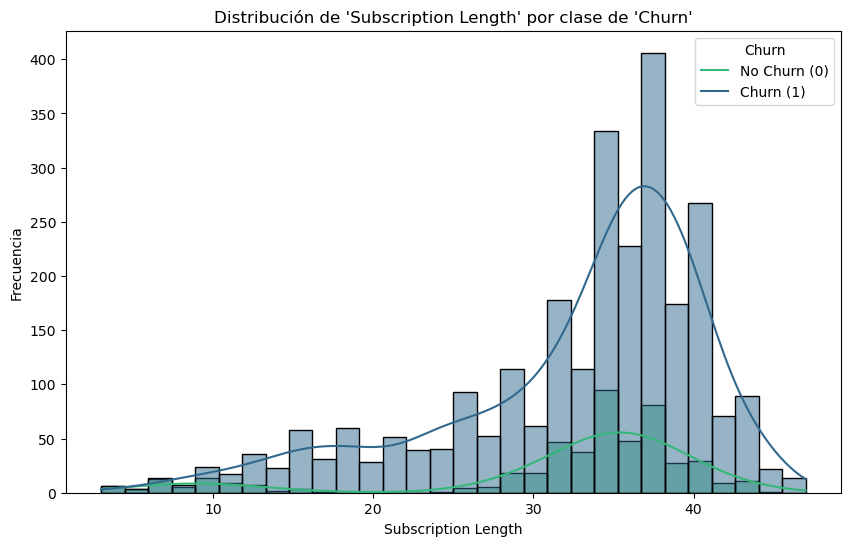

In [137]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='Subscription  Length', hue='Churn', kde=True, bins=30, palette="viridis")
plt.title("Distribución de 'Subscription Length' por clase de 'Churn'")
plt.xlabel("Subscription Length")
plt.ylabel("Frecuencia")
plt.legend(title="Churn", labels=["No Churn (0)", "Churn (1)"])
plt.show()

##### Respecto a los clientes que no cancelaron el servicio - clase 0
- Podemos ver que una mayor duración de la suscripción, se debe a la retención de la suscripción por parte del cliente. Lo podemos ver en el intervalo de 30 a 40 meses de suscripción por parte del cliente. Asismismo, podemos observar que en el intervalo de 30 a 40 meses, se da una distribución relativamente uniforme.
- Por otro lado, podemos observar que se tienen clientes que mantienen suscripciones cortas, aproximadamente de 10 meses por el gráfico.


##### Respecto a los clientes que si cancelaron el servicio - clase 1
- Podemos ver que existe una distribución considerable de clientes con menos de 30 meses de suscripción, por lo cual, podemos deducir que los clientes con menor duración de suscripción son más propensos a abondar el servicio.
- Asimismo, podemos deducir que podría existir un problema de experiencia en el servicio o ausencia de novedades en la suscripción. Debido a que los clientes después de haber probado el servicio por varios meses dejan la suscripción, no durando varios clientes más de 12 meses y, por otro lado, varios clientes después de haber pasados los 30 meses de suscripción abandonan el servicio.

##### Realizamos una estandarizacion de las variables regresoras

In [138]:
df.columns

Index(['Call  Failure', 'Complains', 'Subscription  Length', 'Charge  Amount',
       'Seconds of Use', 'Frequency of use', 'Frequency of SMS',
       'Distinct Called Numbers', 'Age Group', 'Tariff Plan', 'Status', 'Age',
       'Customer Value', 'Churn'],
      dtype='object')

In [139]:
scaler = StandardScaler()

# Estandarizamos los datos 
df_scaled = scaler.fit_transform(df.drop(columns=['Churn']))

# Colocamos los datos en el DataFrame df_scaled
columnas_sin_churn = [col for col in df.columns if col != 'Churn']
df_scaled = pd.DataFrame(df_scaled, columns = columnas_sin_churn)

# Coloco la variable objetivo Churn en el DataFrame
df_scaled['Churn'] = df['Churn']

In [140]:
df_scaled.head()

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
0,0.051229,-0.28783,0.636726,-0.619962,-0.024411,0.026816,-0.607513,-0.378158,0.194941,-0.290409,-0.574662,-0.113074,-0.528759,0
1,-1.050285,-0.28783,0.753384,-0.619962,-0.989807,-1.122926,-0.589691,-1.133331,-0.925616,-0.290409,1.740153,-0.679346,-0.822036,0
2,0.326608,-0.28783,0.520069,-0.619962,-0.481140,-0.164807,2.547012,0.028473,0.194941,-0.290409,-0.574662,-0.113074,2.061285,0
3,0.326608,-0.28783,0.636726,-0.619962,-0.065390,-0.060285,-0.643157,0.667466,-2.046172,-0.290409,-0.574662,-1.811888,-0.446775,0
4,-0.637217,-0.28783,0.636726,-0.619962,-0.495435,-0.199648,-0.634246,0.551285,-2.046172,-0.290409,-0.574662,-1.811888,-0.629033,0


In [141]:
# Debido a keras tenemos que actualizar scikit-learn y imbalanced-learn
# Son por los problemas de ambiente
pip install --upgrade scikit-learn imbalanced-learn

SyntaxError: invalid syntax (2631775016.py, line 3)

#### Pregunta 3

**3**. Muestra la frecuencia de cada clase y realiza un balanceo de clase usando SMOTE. Divida el conjunto de datos en entrenamiento y test, considerando para este último un 33%.

##### Separamos las variables regresoras y la variables objetivo

In [142]:
# variable objetivo y variables regresoras
X = df_scaled.drop(columns=['Churn'])
y = df_scaled['Churn']

In [143]:
# Mostramos la frecuencia de cada clase de la variable objetivo Churn
print("Frecuencia de clases de la variable objetivo Churn antes del balanceo:\n", y.value_counts())

Frecuencia de clases de la variable objetivo Churn antes del balanceo:
 Churn
0    2655
1     495
Name: count, dtype: int64


##### Realizamos un balance de clases usando SMOTE

In [144]:
# from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state = 1234)
X_balanced, y_balanced = smote.fit_resample(X, y)

In [145]:
# Mostramos la frecuencia de cada clase de la variable objetivo Churn despues de aplicar SMOTE
print("Frecuencia de clases de la variable objetivo Churn después del balanceo:\n", y_balanced.value_counts())

Frecuencia de clases de la variable objetivo Churn después del balanceo:
 Churn
0    2655
1    2655
Name: count, dtype: int64


##### Dividimos el conjunto de datos balanceados en entrenamiento y test - 33% para test

In [146]:
X_train, X_test, y_train, y_test = train_test_split(X_balanced, y_balanced, test_size=0.33, random_state=42)

#### Pregunta 4

**4**. Entrene un modelo RandomForest con hiper parámetros por defecto, usando el conjunto de entrenamiento anterior y muestra la métrica F1-Score para ambas 
clases en el conjunto de test. Captura y muestra las siete características ás 
importantes detectadas por el model RandomForest.


In [147]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, classification_report

In [148]:
# Procedemos a entrenar el modelo RandomForestClassifier con hiperparámetros por defecto
model = RandomForestClassifier(random_state=1234)
model.fit(X_train, y_train)

RandomForestClassifier(random_state=1234)

In [149]:
# Realizamos las predicciones en el conjunto de test
y_pred = model.predict(X_test)

In [150]:
# La metrica f1_score para ambas clases la guardamos en la variable f1
f1 = f1_score(y_test, y_pred, average=None)  # average=None para F1-Score de cada clase

# Mostramos la metrica F1-Score para ambas clases en el conjunto de test
print("F1 Score para cada clase:")
for i, f1_score in enumerate(f1):
    print(f"Clase {i}: {f1_score:.4f}")

F1 Score para cada clase:
Clase 0: 0.9794
Clase 1: 0.9796


##### Captura y muestra las siete características más importantes detectadas por el modelo RandomForest

In [151]:
# Capturamos las caracteristicas mas importante detectadas por el modelo RandomForest

importancia_variables = model.feature_importances_
importancia_variables = pd.Series(importancia_variables, index = X_train.columns)
importancia_variables.sort_values(ascending = False, inplace = True)

In [152]:
importancia_variables

Status                     0.172118
Frequency of use           0.122029
Complains                  0.116547
Subscription  Length       0.112634
Customer Value             0.108689
Seconds of Use             0.102505
Distinct Called Numbers    0.070238
Frequency of SMS           0.063607
Call  Failure              0.047288
Age Group                  0.032285
Age                        0.026295
Charge  Amount             0.023785
Tariff Plan                0.001981
dtype: float64

In [153]:
# Capturamos las 7 características mas importantes detectadas por el modelo RandomForest.

importancia_variables_7 = importancia_variables.head(7)
importancia_variables_7 

Status                     0.172118
Frequency of use           0.122029
Complains                  0.116547
Subscription  Length       0.112634
Customer Value             0.108689
Seconds of Use             0.102505
Distinct Called Numbers    0.070238
dtype: float64

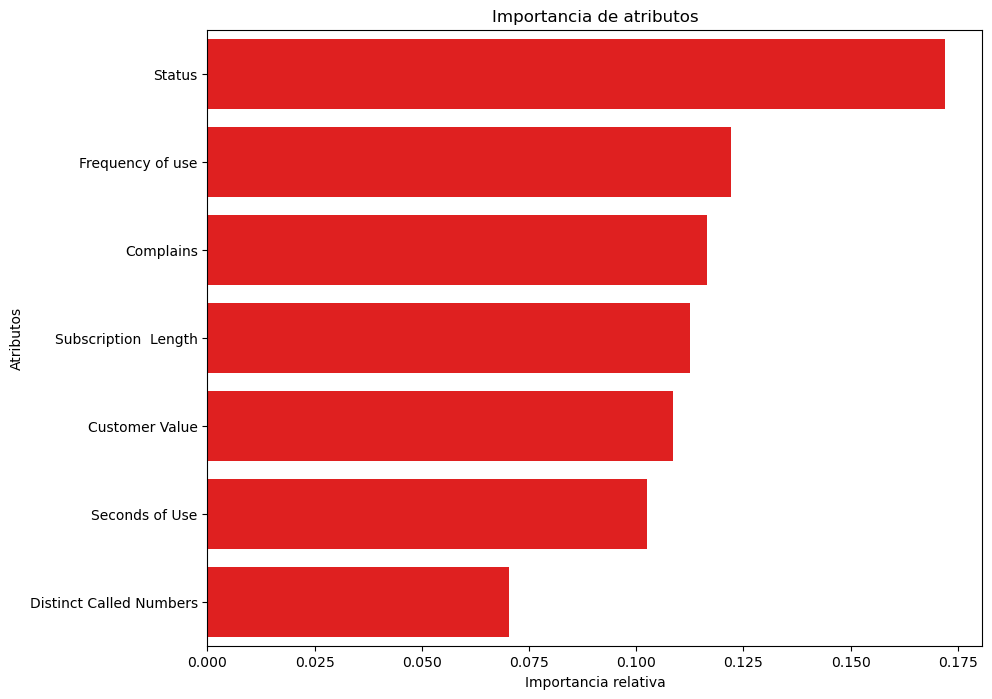

In [154]:
# Mostramos las 7 características mas importantes detectadas por el modelo RandomForest.

plt.figure(figsize = (10, 8))
sns.barplot(x = importancia_variables_7, y = importancia_variables_7.index, color = 'red')
plt.title('Importancia de atributos')
plt.xlabel('Importancia relativa')
plt.ylabel('Atributos')
plt.show()

#### Pregunta 5

**5**. Usando las siete características encontradas anteriormente, filtra el conjunto de entrenamiento y entrena un modelo de red neuronal feedforward con sólo una capa oculta. Para esto debes definir una función de activación adecuada, tanto para la capa oculta como para la capa de salida, la cantidad de neuronas a usar, la tasa de aprendizaje (learning_rate), y la cantidad de épocas deben ser ajustadas manualmente. Como optimizador, utiliza el Descenso del Gradiente Estocástico. Los ajustes manuales de los hiper parámetros deben ser tales que la métrica AUC sea mayor al 90%. Muestra finalmente ROC y su AUC. (3 Puntos)

In [155]:
importancia_variables_7.index

Index(['Status', 'Frequency of use', 'Complains', 'Subscription  Length',
       'Customer Value', 'Seconds of Use', 'Distinct Called Numbers'],
      dtype='object')

In [156]:
variables_utilizar = importancia_variables_7.index

In [157]:
X_7 = X[variables_utilizar]

In [158]:
X_7.head()

,Status,Frequency of use,Complains,Subscription Length,Customer Value,Seconds of Use,Distinct Called Numbers
0,-0.574662,0.026816,-0.28783,0.636726,-0.528759,-0.024411,-0.378158
1,1.740153,-1.122926,-0.28783,0.753384,-0.822036,-0.989807,-1.133331
2,-0.574662,-0.164807,-0.28783,0.520069,2.061285,-0.481140,0.028473
3,-0.574662,-0.060285,-0.28783,0.636726,-0.446775,-0.065390,0.667466
4,-0.574662,-0.199648,-0.28783,0.636726,-0.629033,-0.495435,0.551285


##### Realizamos un balance de clases usando SMOTE

In [159]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state = 1234)
X_balanced_7, y_balanced = smote.fit_resample(X_7, y)

In [160]:
y.value_counts()

Churn
0    2655
1     495
Name: count, dtype: int64

In [161]:
y_balanced.value_counts()

Churn
0    2655
1    2655
Name: count, dtype: int64

In [162]:
X_train, X_test, y_train, y_test = train_test_split(X_balanced_7, y_balanced, test_size=0.33, random_state=1234)

In [163]:
# Importación de librerias para el desarrollo de red neuronal artificial

# import tensorflow as tf
# from keras.models import Sequential
# from keras.layers import Dense
# from keras.optimizers import SGD
# import keras

##### Definimos la arquitectura de la red neuronal:
Esta función recibe tres parámetros:
- unit: El número de neuronas (o unidades) en cada capa oculta.
- active: La función de activación que se usará en las capas ocultas.
- capas: El número de capas ocultas que tendrá la red neuronal. Por defecto, hemos colocado capa = 1, debido a que el problema 5 nos pide solamente usar 1 solo capa oculta.

In [164]:
def modelo_ann(unit, active, capas = 1):
    
    ann = Sequential()

    # Capa de entrada
    ann.add(keras.Input(shape = (X_train.shape[1],))) # Ese 1 está ahí para traer el número de columnas de los datos de entrada

    # Capa oculta
    for i in range(capas):
        ann.add(Dense(units = unit, activation = active, use_bias = True))

    # Salida
    ann.add(Dense(units = 1, activation = 'sigmoid', use_bias = True))

    # la función devuelve el modelo neuronal construido con las capas que se agregaron.
    return ann

In [165]:
ann = modelo_ann(unit = 120, active = 'relu')

##### Configuramos el proceso de aprendizaje de la red neuronal

Por lo cual, procedemos a especificar el optimizador y la función de pérdida que se utilizarán durante el entrenamiento del modelo.
- En este caso utilizaremos SGD que significa Stochastic Gradient Descent (Descenso de Gradiente Estocástico), que es un algoritmo de optimización usado para ajustar los pesos de la red neuronal durante el entrenamiento.
- Por otro lado, utilizaremos un learning_rate = 0.001, la cual es la tasa de aprendizaje que controla el tamaño de los pasos que el optimizador toma en la dirección opuesta al gradiente.

Funcion de perdida
- Para la función de pérdida utilizaremos binary_crossentropy, la cual es la entropía cruzada binaria, una función de pérdida comúnmente utilizada en problemas de clasificación binaria.
- La función de pérdida mide qué tan bien está funcionando el modelo comparando las predicciones con los valores reales. El objetivo del entrenamiento de un modelo es minimizar esta función de pérdida conforme se vayan recorriendo las épocas y se después un back propagation y se siga repitiendo este ciclo.

In [166]:
ann.compile(optimizer = SGD(learning_rate = 0.001), loss = 'binary_crossentropy')

# Entrenamos la red neuronal
ann.fit(X_train, y_train, verbose = 1, epochs = 350)

Epoch 1/350
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.6851
Epoch 2/350
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.6394
Epoch 3/350
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.6064
Epoch 4/350
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.5787
Epoch 5/350
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.5585
Epoch 6/350
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.5349
Epoch 7/350
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.5179
Epoch 8/350
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.5097
Epoch 9/350
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.5000
Epoch 10/350
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4844
Epoch 11/350
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4755
Epoch 12/350
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4652
Epoch 13/350
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4636
Epoch 14/350
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4560
Epoch 15/350
112/112 ━━━━━━━━━━━━━━━━━━━━ 0

Dado que el modelo fue configurado con una capa de salida sigmoide (que devuelve valores entre 0 y 1), las predicciones serán valores continuos entre 0 y 1, lo que representa la probabilidad de que cada ejemplo pertenezca a la clase 1.
- y_pred_nn: Este es el vector de predicciones, donde cada elemento es una probabilidad (un valor entre 0 y 1) que el modelo predice para el conjunto de prueba X_test.
- Si un valor en y_pred_nn es igual a 0.85, significa que el modelo predice que hay un 85% de probabilidad de que ese ejemplo pertenezca a la clase 1.

In [167]:
y_pred_nn = ann.predict(X_test)
y_pred_nn

55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


array([[0.71945655],
       [0.02838262],
       [0.3200459 ],
       ...,
       [0.75875634],
       [0.00925476],
       [0.7424184 ]], dtype=float32)

In [168]:
# Importamos la libreria para hacer desarrollar el ROC y AUC
from sklearn.metrics import roc_curve, roc_auc_score

##### Calculamos el AUC

In [169]:
auc = roc_auc_score(y_test, y_pred_nn)
print(f"AUC: {auc:.3f}")

AUC: 0.938


El AUC al ser superior a 0.9, indica un buen desempeño.

##### Calculamos la Curva ROC

In [170]:
# fpr -> tasa de falsos positivos
# tpr -> tasa de verdaderos positivos
# threshold -> umbral de decisión
fpr, tpr, threshold = roc_curve(y_test, y_pred_nn)


##### Graficamos de la curva ROC

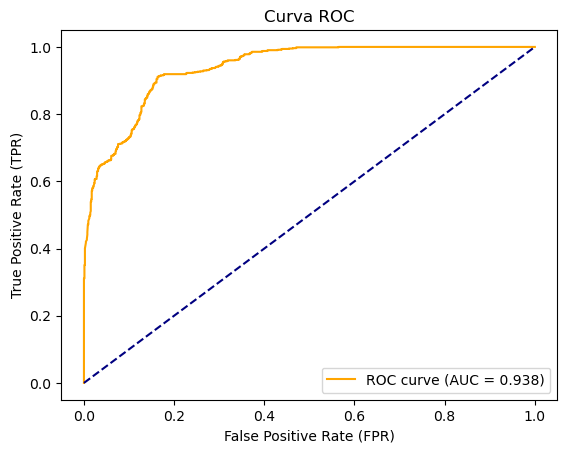

In [171]:
plt.figure()
plt.plot(fpr, tpr, color='orange', label=f'ROC curve (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')  # Línea de referencia
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Curva ROC')
plt.legend(loc="lower right")
plt.show()